# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import C2SegDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt
import numpy as np
import scipy.io

## Visualize images and masks

In [ ]:
dataset_config = {
    "mat_file": "./data/c2seg/data2/beijing.mat",
}
dataset = C2SegDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1768


## Show images

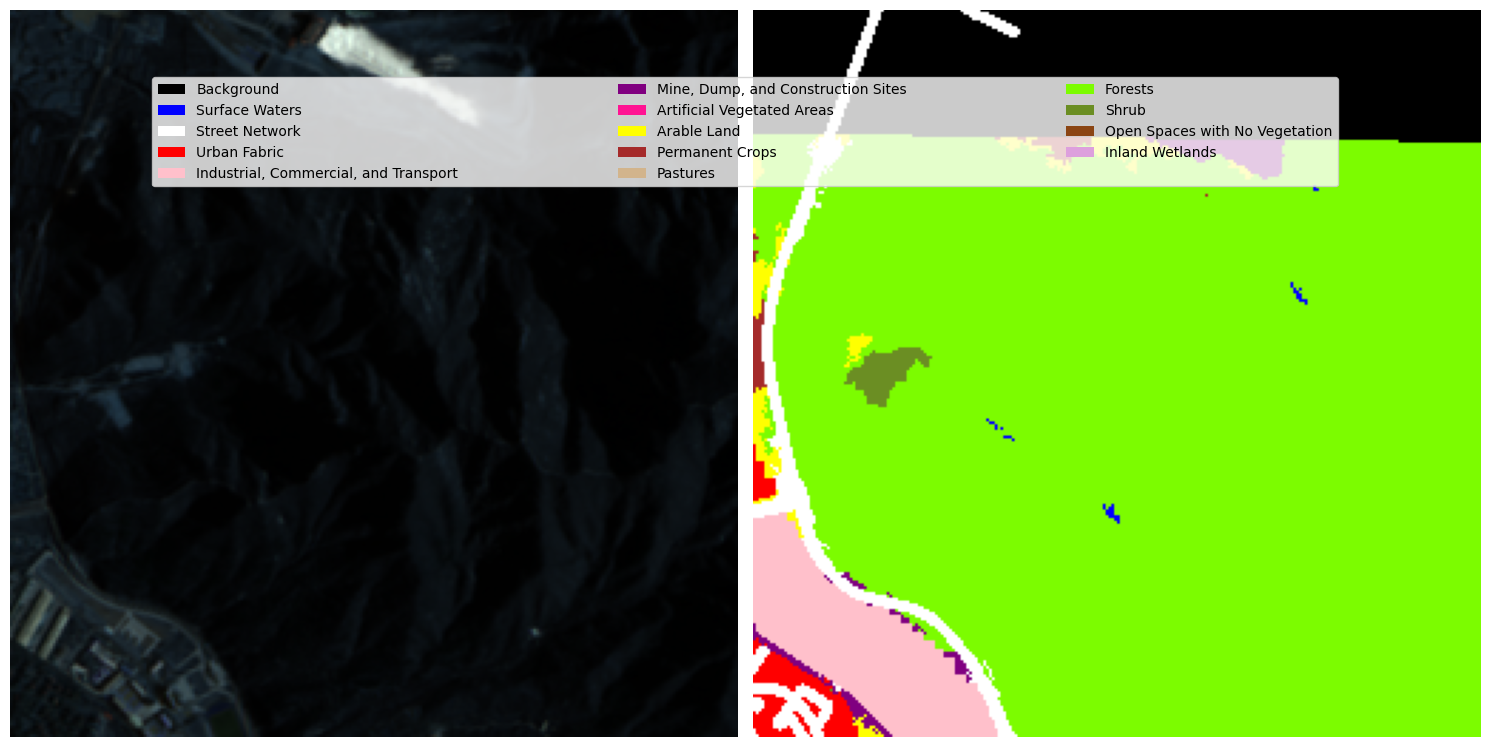

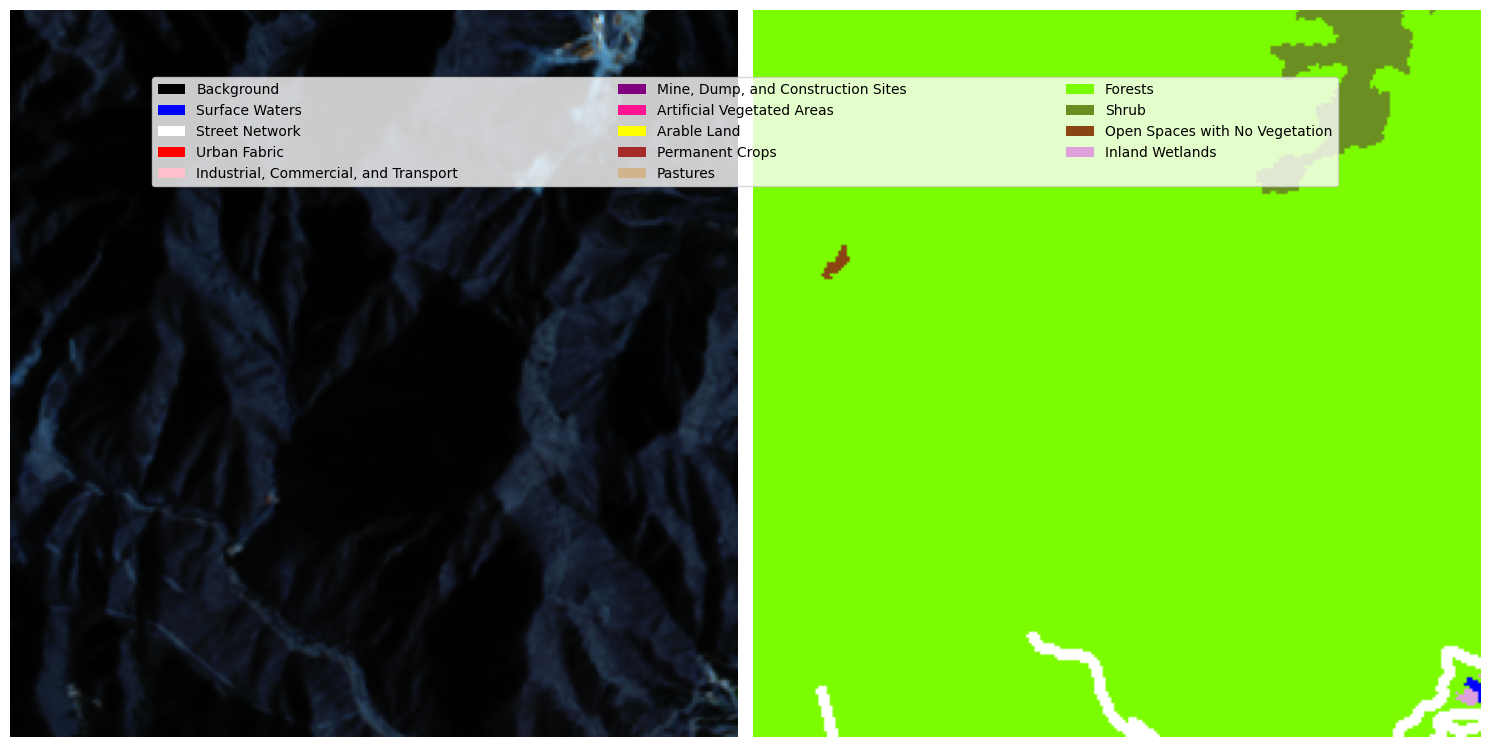

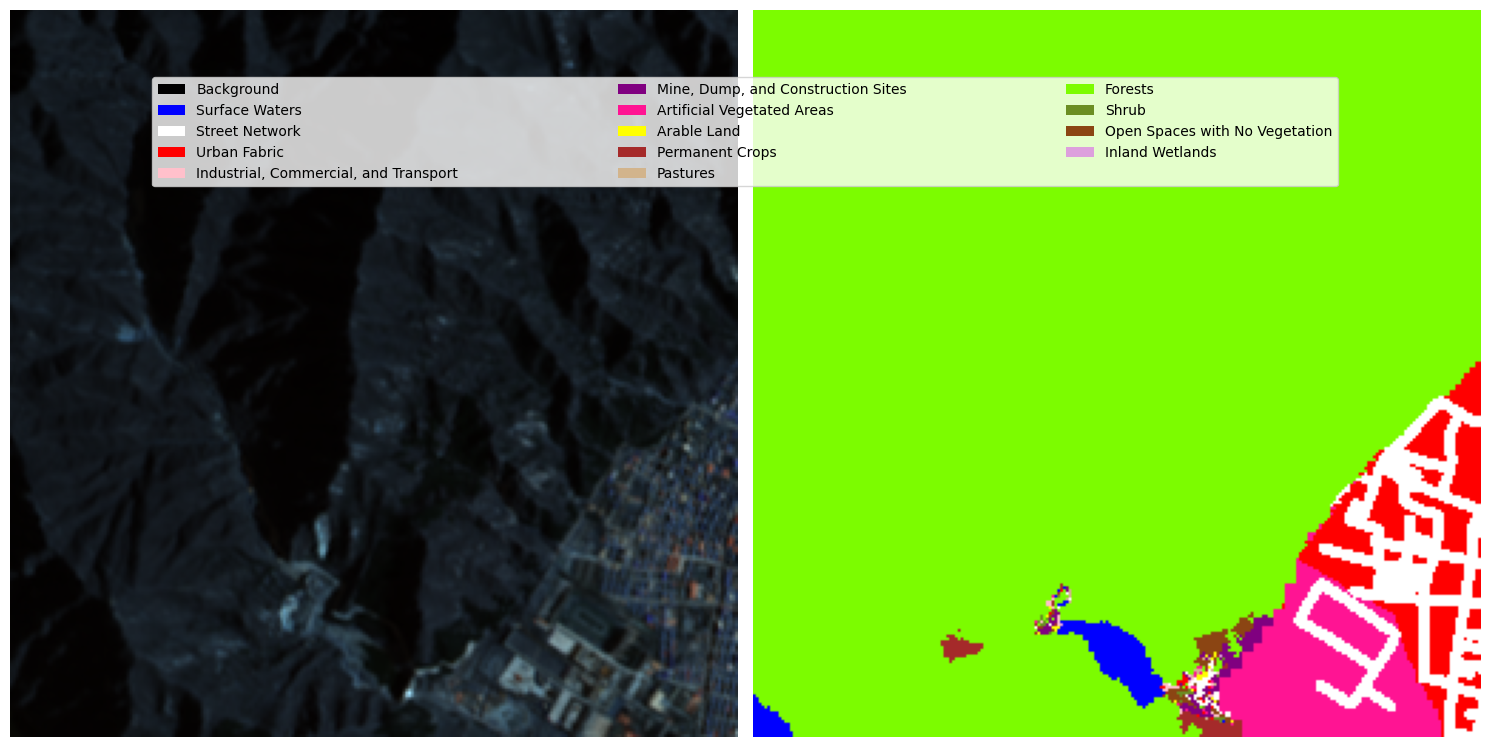

In [18]:
dataset.show_image(15)
dataset.show_image(150)
dataset.show_image(281);

In [ ]:
dataset.data_distribution_table()

,Number of pixels
Background,1771782
Surface Waters,2300645
Street Network,10653198
Urban Fabric,16499310
"Industrial, Commercial, and Transport",7347342
"Mine, Dump, and Construction Sites",4052457
Artificial Vegetated Areas,12541099
Arable Land,6217906
Permanent Crops,3851609
Pastures,162696


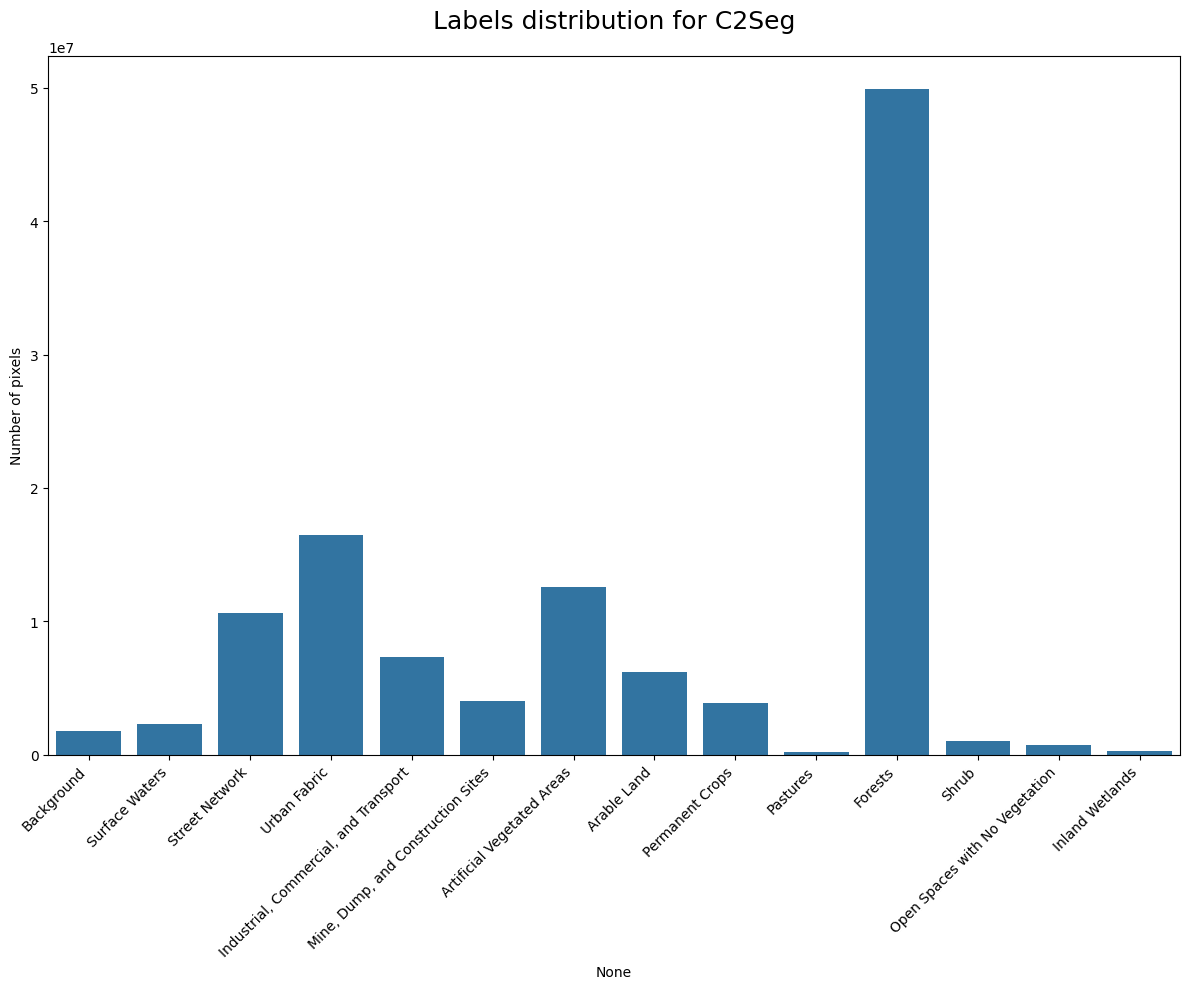

In [ ]:
dataset.data_distribution_barchart();

Total number of patches: 27


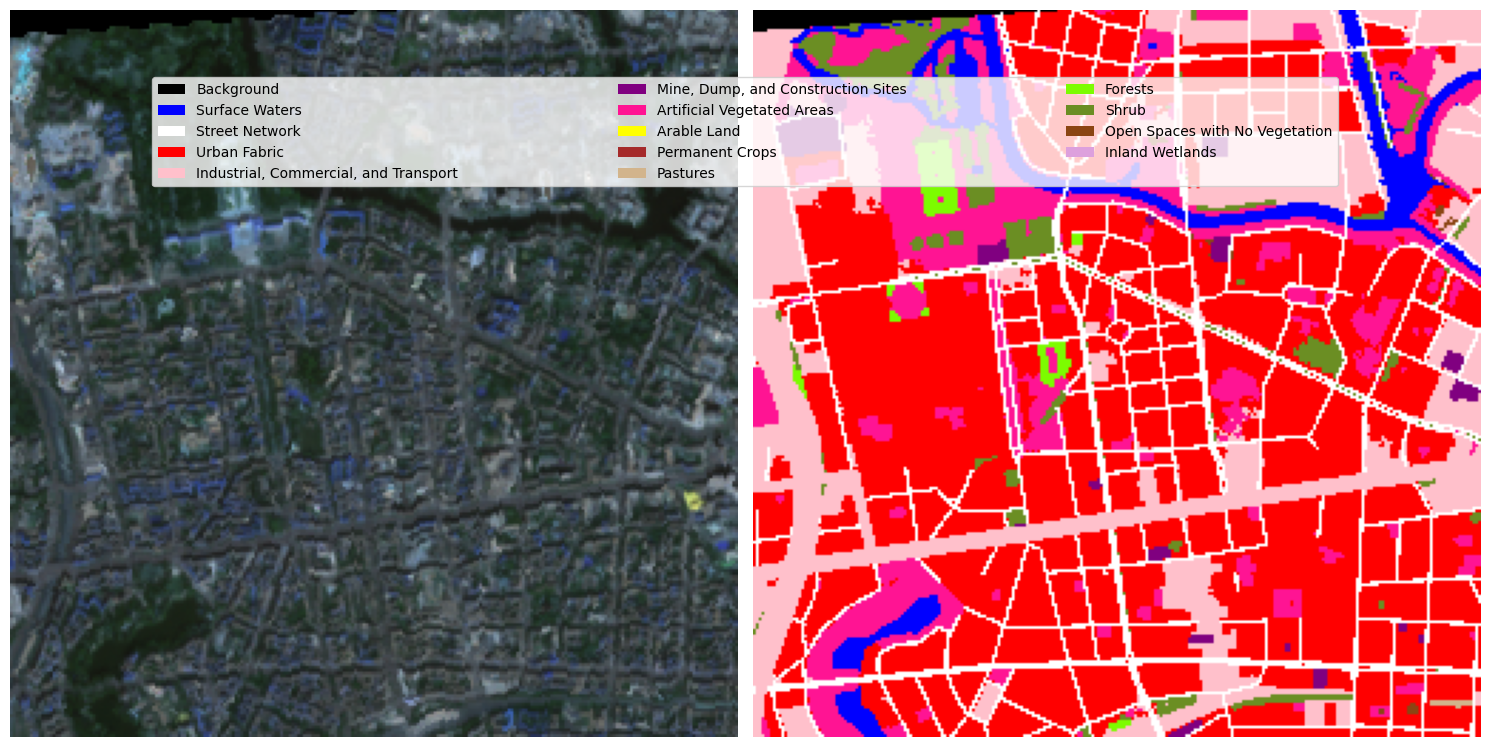

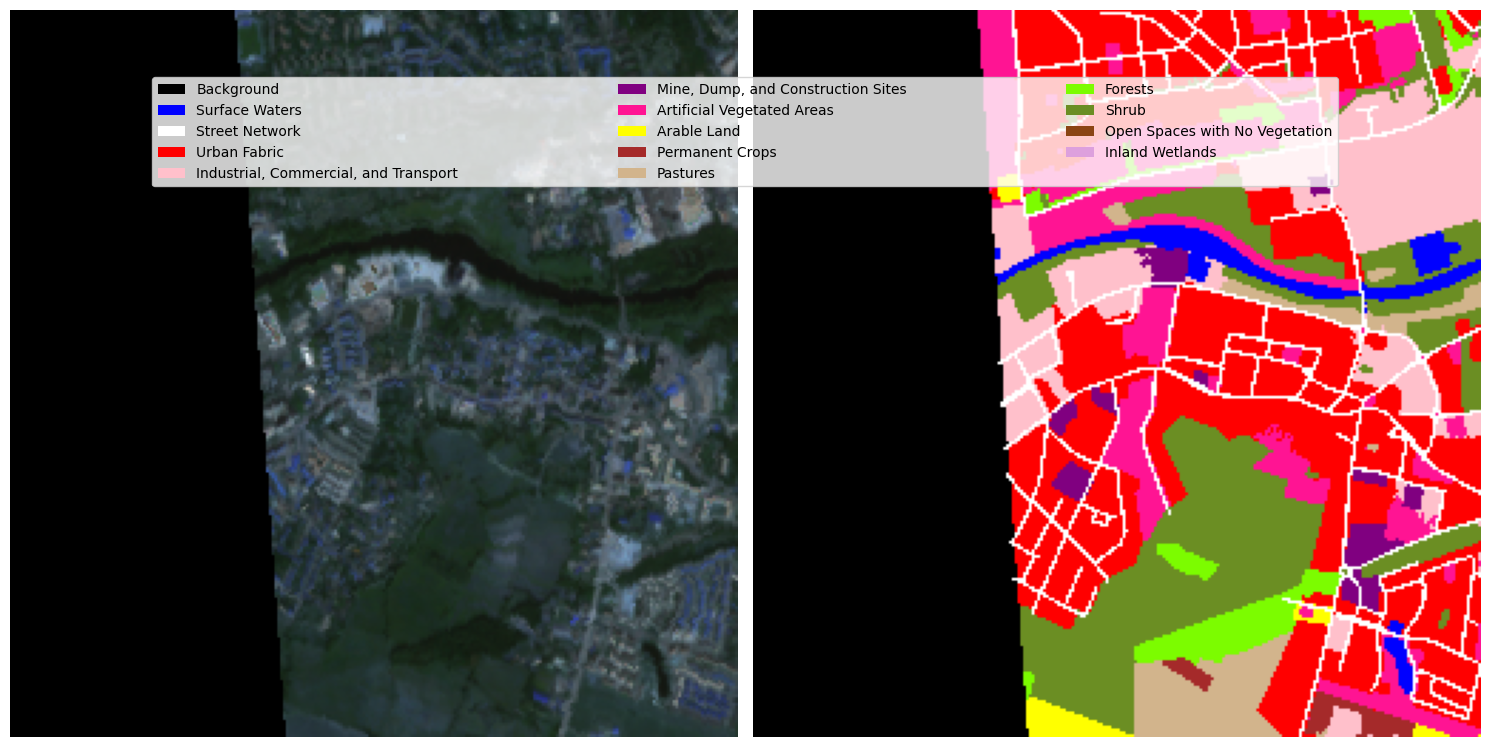

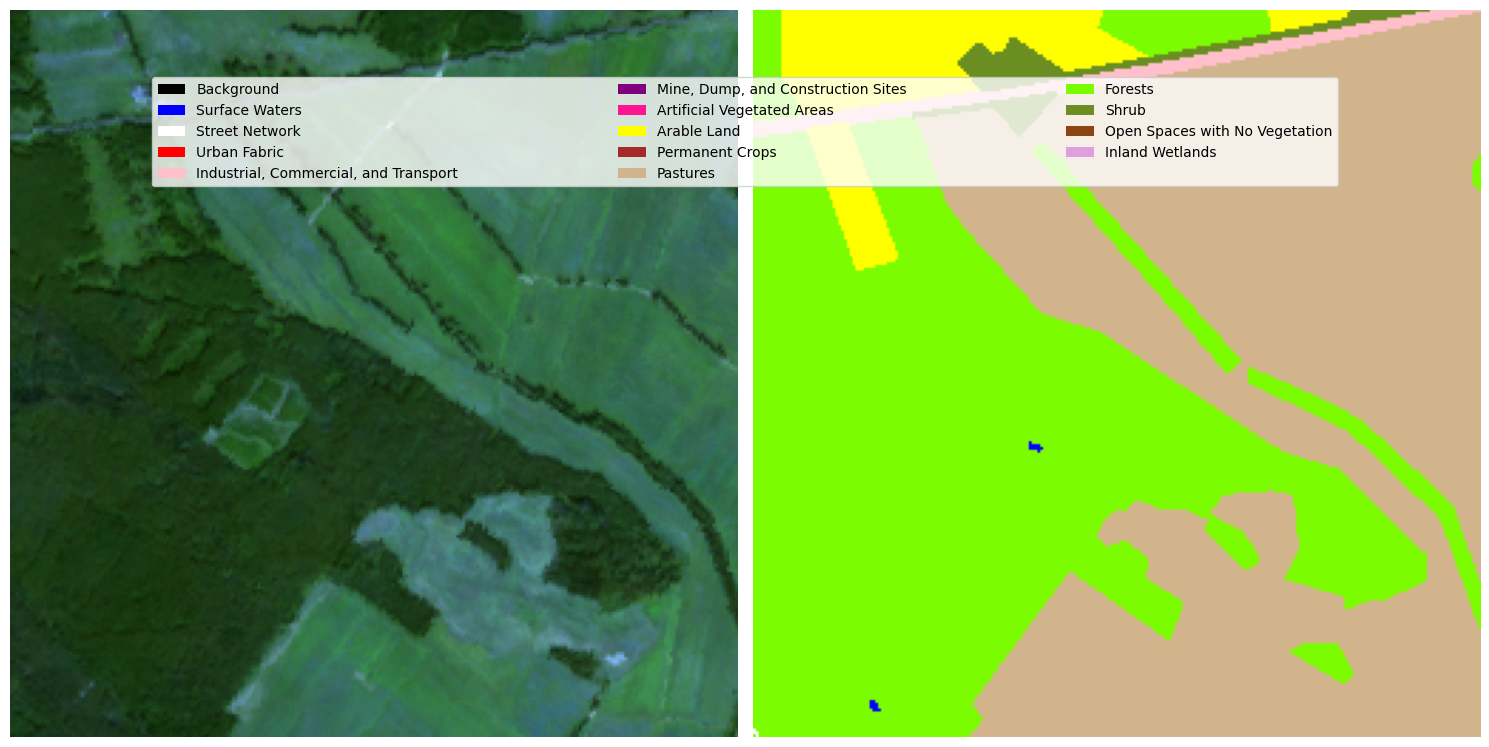

In [ ]:
dataset_config2 = {
    "mat_file": "./data/c2seg/data1/berlin_multimodal.mat",
}
dataset2 = C2SegDataset(dataset_config2)

print(f"Total number of patches: {len(dataset2)}")

dataset2.show_image(1)
dataset2.show_image(15)
dataset2.show_image(26);

In [ ]:
dataset2.data_distribution_table()

,Number of pixels
Background,384800
Surface Waters,18375
Street Network,121085
Urban Fabric,525989
"Industrial, Commercial, and Transport",191691
"Mine, Dump, and Construction Sites",21745
Artificial Vegetated Areas,135126
Arable Land,190256
Permanent Crops,2704
Pastures,90527


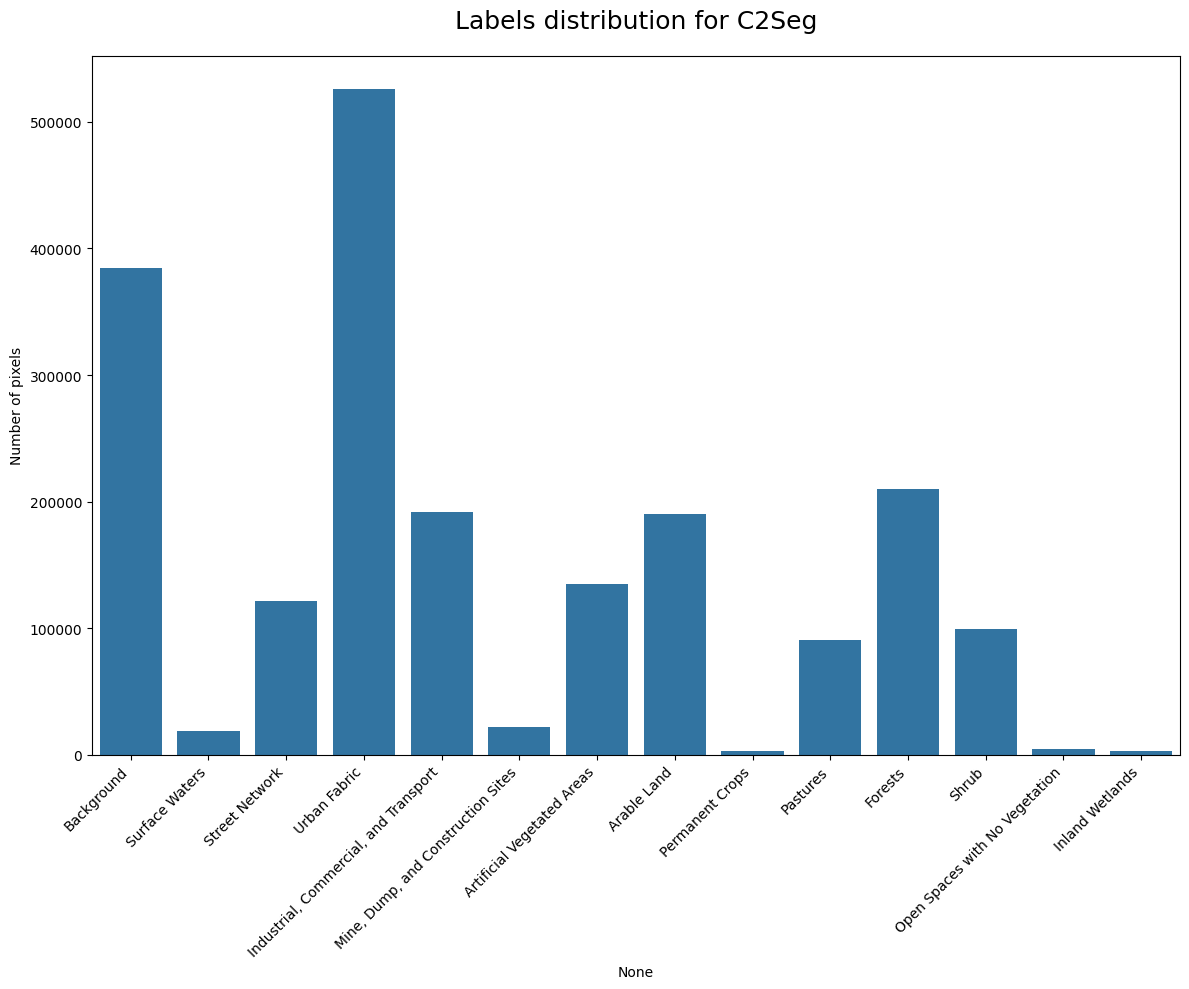

In [ ]:
dataset2.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "mat_file": "./data/c2seg/data2/beijing.mat",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = C2SegDataset(train_dataset_config)
len(train_dataset)

1768

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/C2Seg"
model_config = {
    "num_classes": 14, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-08-20 07:03:11,945 INFO Starting training.
training: 100%|██████████| 442/442 [58:04<00:00,  7.88s/it]
2025-08-20 08:01:16,050 INFO epoch: 1, time: 3484, loss:  0.72137
testing on train set: 100%|██████████| 442/442 [58:15<00:00,  7.91s/it] 
2025-08-20 08:59:34,085 INFO IOU:0.32062124840367356, IOU mean:0.11588404135264883, IOU per Class:[0.         0.         0.15867752 0.29534548 0.12262017 0.
 0.19070637 0.14093797 0.         0.         0.71408907 0.
 0.         0.        ]
training: 100%|██████████| 442/442 [58:12<00:00,  7.90s/it]
2025-08-20 09:57:46,245 INFO epoch: 2, time: 3492, loss:  0.53076
testing on train set: 100%|██████████| 442/442 [58:02<00:00,  7.88s/it]  
2025-08-20 10:55:48,455 INFO IOU:0.3933671040039642, IOU mean:0.07768839620037925, IOU per Class:[0.00000000e+00 0.00000000e+00 0.00000000e+00 3.48746805e-01
 0.00000000e+00 0.00000000e+00 5.93894733e-04 0.00000000e+00
 0.00000000e+00 0.00000000e+00 7.38296847e-01 0.00000000e+00
 0.00000000e+00 0.00000000e+00]
t

0.37185796367097224

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "mat_file": "./data/c2seg/data2/wuhan.mat",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = C2SegDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/C2Seg/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

792


2025-08-21 06:43:27,282 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/C2Seg/checkpoint.pth.tar
2025-08-21 06:43:27,749 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/C2Seg/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 198/198 [07:39<00:00,  2.32s/it]


[{'IOU': 0.03772824841428524,
  'IOU mean': 0.017214824615058154,
  'IOU per Class': array([0.        , 0.        , 0.        , 0.02878403, 0.        ,
         0.        , 0.04547938, 0.12900881, 0.        , 0.        ,
         0.03773532, 0.        , 0.        , 0.        ])}]

## Predictions

2025-08-21 07:01:03,847 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/C2Seg/checkpoint.pth.tar
2025-08-21 07:01:04,271 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/C2Seg/checkpoint.pth.tar at epoch 11


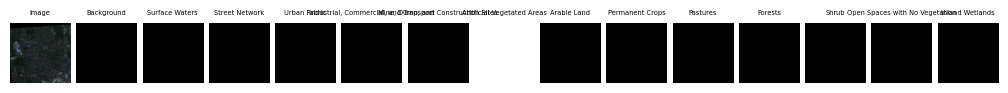

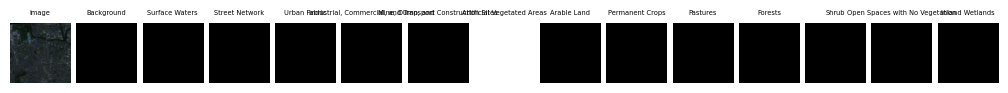

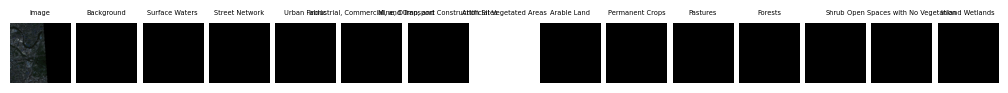

In [ ]:
model_path = "./data/experiments/C2Seg/checkpoint.pth.tar"
labels = ["Background",
    "Surface Waters",
    "Street Network",
    "Urban Fabric",
    "Industrial, Commercial, and Transport",
    "Mine, Dump, and Construction Sites",
    "Artificial Vegetated Areas",
    "Arable Land",
    "Permanent Crops",
    "Pastures",
    "Forests",
    "Shrub",
    "Open Spaces with No Vegetation",
    "Inland Wetlands"]
IMG_H, IMG_W = 256, 256
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})
mat = scipy.io.loadmat("./data/c2seg/data1/berlin_multimodal.mat")
scene = mat['MSI']
height, width = scene.shape[: 2]
data = []
stride = IMG_H

for y in range(0, height - IMG_H + 1, stride):
    for x in range(0, width - IMG_W + 1, stride):
        if y + IMG_H <= height and x + IMG_W <= width:
            data.append((x,y))
for i in np.arange(3):
    x,y = data[i]
    image = scene[y:y+IMG_H, x:x+IMG_W, :3]/5000
    fig = model.predict_masks(image, labels, transform)